# Simulation of Faraday rotation per landcover

In [ ]:
"""
File Name: pol_simulate_FR_per_landcover.py

Authors:
    Juan M. Lopez-Sanchez
    University of Alicante

Date: July 2025

Description:
------------
This script analyses the effect of the injection of Faraday Rotation on ideal
dual-pol VV-VH data defined for typical land-covers.

The original polarimetric data (quad-pol covariance matrix) characterising
each land-cover type are defined in:

A. Freeman, "Calibration of linearly polarized polarimetric SAR data subject
to Faraday rotation," IEEE Transactions on Geoscience and Remote Sensing,
vol. 42, no. 8, pp. 1617-1624, Aug. 2004, doi: 10.1109/TGRS.2004.830161

This script computes the result of injecting a one-way rotation
angle, ranging from 0 to a value defined  by the user (e.g. 20 degrees),
providing four output dual-pol variables:

    Backscattering coefficient of VV channel (dB)
    Backscattering coefficient of VH channel (dB)
    Normalized correlation between VV and VH channels
    Phase difference between VV and VH channels (degrees)

The four variables are plotted vs the FR angle.

Dependencies:
-------------
- numpy
- matplotlib.pyplot


Usage:
------
To use this script, define the following parameters:

    - land_cover: Choose among 'Bare soil', 'Upland Forest', and 'Swamp Forest'
    - max_FR_angle: Maximum one-way FR angle (degrees), e.g. 20.
"""

Package dependencies

In [1]:
import numpy as np
import matplotlib.pyplot as plt

User-defined input parameters

In [2]:
########################
# PARAMETERS
########################

land_cover = "Bare soil"
max_FR_angle = 20

Format of values and selection of the land cover type parameters

In [3]:
# Interval of Faraday rotation angles (in degrees)

Omega_deg = np.linspace(0, max_FR_angle, max_FR_angle + 1)
Omega = Omega_deg * np.pi / 180.0

cosO = np.cos(Omega)
sinO = np.sin(Omega)

# Ideal quad-pol covariance matrix of land cover types.

# Table from (Freeman, 2004)

if land_cover == "Bare soil":

    s0HH = -16.5  # dB
    s0VV = -14.7  # dB
    s0VH = -26.9  # dB
    rho_co = 0.75
    phase_co = -23.7  # degrees
    rho_cox = 0.0  # Reflection symmetry
    phase_cox = 0

elif land_cover == "Upland Forest":

    s0HH = -9.2  # dB
    s0VV = -9.4  # dB
    s0VH = -14.3  # dB
    rho_co = 0.25
    phase_co = 7.9  # degrees
    rho_cox = 0.0  # Reflection symmetry
    phase_cox = 0

elif land_cover == "Swamp Forest":

    s0HH = -6.9  # dB
    s0VV = -7.3  # dB
    s0VH = -14.5  # dB
    rho_co = 0.06
    phase_co = 165.4  # degrees
    rho_cox = 0.0  # Reflection symmetry
    phase_cox = 0

# Convert sigma0 to linear scale and phase to radians

s0HH = 10 ** (s0HH / 10)
s0VV = 10 ** (s0VV / 10)
s0VH = 10 ** (s0VH / 10)

phase_co *= np.pi / 180.0
phase_cox *= np.pi / 180.0

Ideal dual-pol covariance matrix

In [4]:
C_11 = s0VV
C_22 = s0VH
C_12 = np.sqrt(s0VV * s0VH) * rho_cox * np.exp(1j * phase_cox)

Injection of Faraday rotation

In [5]:
# Option 1: Assuming null co-cross correlation without FR

cosO = np.cos(Omega)
sinO = np.sin(Omega)

C_11_FR = (
    cosO**4 * s0VV
    + sinO**4 * s0HH
    - 2 * sinO**2 * cosO**2 * np.sqrt(s0VV * s0HH) * rho_co * np.cos(phase_co)
)

C_22_FR = s0VH + sinO**2 * cosO**2 * (
    s0HH + s0VV + 2 * np.sqrt(s0VV * s0HH) * rho_co * np.cos(phase_co)
)

C_12_FR = sinO**3 * cosO * (
    s0HH + np.sqrt(s0VV * s0HH) * rho_co * np.exp(-1j * phase_co)
) - sinO * cosO**3 * (s0VV + np.sqrt(s0VV * s0HH) * rho_co * np.exp(1j * phase_co))

In [6]:
# Option 2: Without assumptions on the co-cross correlation

C_11_FR = (
    cosO**4 * s0VV
    + sinO**4 * s0HH
    - 2 * sinO**2 * cosO**2 * np.sqrt(s0VV * s0HH) * rho_co * np.cos(phase_co)
)

C_22_FR = (
    s0VH
    + sinO**2
    * cosO**2
    * (s0HH + s0VV + 2 * np.sqrt(s0VV * s0HH) * rho_co * np.cos(phase_co))
    - sinO
    * cosO
    * (
        2 * np.sqrt(s0HH * s0VH) * rho_cox * np.cos(phase_cox)
        + 2 * np.sqrt(s0VV * s0VH) * rho_cox * np.cos(phase_cox)
    )
)

C_12_FR = (
    sinO**3 * cosO * (s0HH + np.sqrt(s0VV * s0HH) * rho_co * np.exp(-1j * phase_co))
    - sinO * cosO**3 * (s0VV + np.sqrt(s0VV * s0HH) * rho_co * np.exp(1j * phase_co))
    + cosO**2 * np.sqrt(s0VV * s0VH) * rho_cox * np.exp(1j * phase_cox)
    - sinO**2 * np.sqrt(s0HH * s0VH) * rho_cox * np.exp(1j * phase_cox)
)

Show output values

In [7]:
print(C_11, C_22, C_12)
print(C_11_FR, C_22_FR, C_12_FR)

C_11_FR_dB = 10 * np.log10(C_11_FR)
C_22_FR_dB = 10 * np.log10(C_22_FR)

cx_rho_cox_FR = C_12_FR / np.sqrt(C_11_FR * C_22_FR)

rho_cox_FR = np.abs(cx_rho_cox_FR)
phase_cox_FR = np.angle(cx_rho_cox_FR) * 180 / np.pi

0.033884415613920256 0.0020417379446695297 0j
[0.03388442 0.03385226 0.03375594 0.03359588 0.03337281 0.03308771
 0.03274186 0.03233682 0.03187438 0.0313566  0.03078581 0.03016453
 0.02949554 0.0287818  0.02802649 0.02723295 0.02640469 0.02554537
 0.02465877 0.02374881 0.02281945] [0.00204174 0.00207039 0.00215621 0.00229878 0.0024974  0.00275111
 0.00305867 0.00341858 0.00382909 0.00428819 0.00479366 0.00534303
 0.00593362 0.00656256 0.00722677 0.00792304 0.00864795 0.00939799
 0.01016949 0.01095871 0.01176178] [ 0.        +0.j         -0.00092083+0.00014488j -0.00183754+0.00028959j
 -0.00274603+0.00043395j -0.00364224+0.00057777j -0.00452216+0.00072089j
 -0.00538188+0.00086314j -0.00621756+0.00100433j -0.00702549+0.0011443j
 -0.00780209+0.00128287j -0.00854392+0.00141988j -0.00924772+0.00155516j
 -0.0099104 +0.00168855j -0.01052906+0.00181988j -0.01110104+0.00194899j
 -0.01162386+0.00207573j -0.0120953 +0.00219994j -0.01251338+0.00232147j
 -0.01287637+0.00244017j -0.0131828 +0.002555

FIGURES

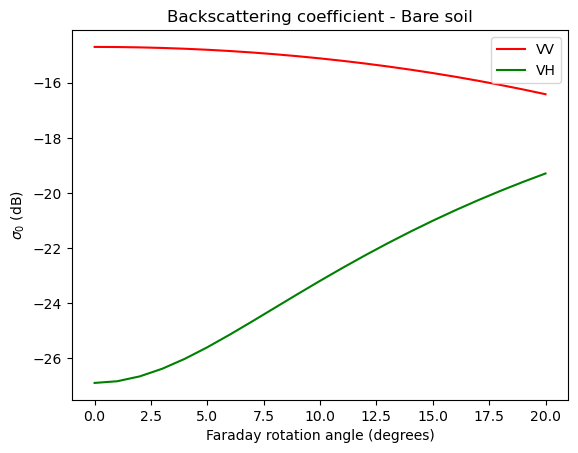

In [8]:
# Backscattering coefficient

fig, ax = plt.subplots()

ax.set_title("Backscattering coefficient - " + land_cover)

ax.plot(Omega_deg, C_11_FR_dB, color="r", label="VV")
ax.plot(Omega_deg, C_22_FR_dB, color="g", label="VH")

ax.set_xlabel("Faraday rotation angle (degrees)")
ax.set_ylabel("$\sigma_0$ (dB)")

ax.legend()

(0.0, 1.0)

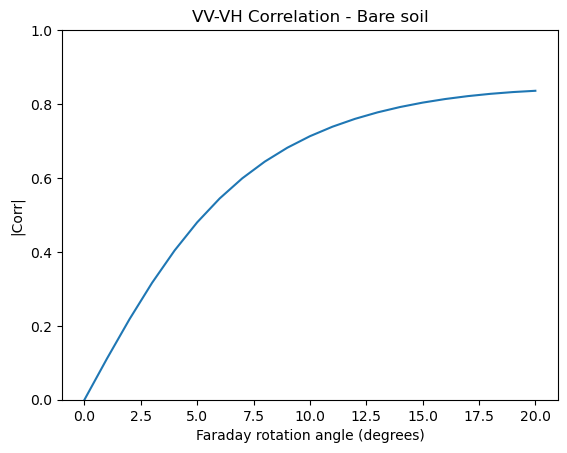

In [9]:
# Correlation between channels

fig, ax = plt.subplots()

ax.set_title("VV-VH Correlation - " + land_cover)

ax.plot(Omega_deg, rho_cox_FR)

ax.set_xlabel("Faraday rotation angle (degrees)")
ax.set_ylabel("|Corr|")
ax.set_ylim([0, 1])

Text(0, 0.5, 'arg(Corr) [deg]')

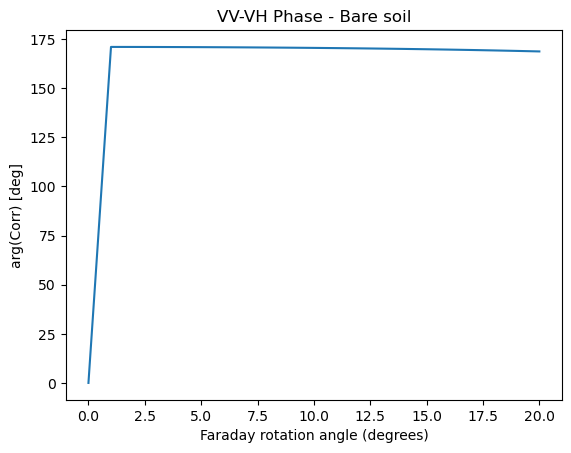

In [10]:
# Phase between channels

fig, ax = plt.subplots()

ax.set_title("VV-VH Phase - " + land_cover)

ax.plot(Omega_deg, phase_cox_FR)

ax.set_xlabel("Faraday rotation angle (degrees)")
ax.set_ylabel("arg(Corr) [deg]")